In [22]:
import os
from pathlib import Path

# Let's inspect what folders actually exist in your MyDrive
mydrive_path = Path("/content/drive/MyDrive")

try:
    print("Folders available in MyDrive:")
    existing_dirs = [x.name for x in mydrive_path.iterdir() if x.is_dir()]
    for folder in sorted(existing_dirs):
        print(f" - {folder}")
except FileNotFoundError:
    print("Google Drive is not mounted yet. Please run the cell containing drive.mount() first.")

Folders available in MyDrive:
 - 2animaldataset
 - All Nepal University Cup- Registration (File responses)
 - Audio overviews
 - Books in mobile
 - CNNDomesticAnimalsDataset
 - Classroom
 - Colab Notebooks
 - College documnets for US
 - ENgg 112
 - Google Meet
 - MTechAI
 - Patient Doctor communication 
 - Resumes & Applications
 - S69570
 - math.zip (Unzipped Files)
 - new11111
 - nirmla bb


In [2]:
# Option 1: Mount your Google Drive to access your folders directly
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
folder_path = "/content/drive/MyDrive/2animaldataset"
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'}

# folder_names = []
path = Path(folder_path)
sub_folders = [x for x in path.iterdir() if x.is_dir()]
sub_folder_label = [x.name.split("/")[-1] for x in sub_folders]
print(f"Total folders found: {len(sub_folders)}")
for path in sub_folders:
    print(path)

print(f"sub folder label", sub_folder_label)

Total folders found: 2
/content/drive/MyDrive/2animaldataset/Chicken
/content/drive/MyDrive/2animaldataset/Cat
sub folder label ['Chicken', 'Cat']


In [4]:
image_class = sub_folder_label
print("classes of image: ",  image_class, "\nlength of the class", len(image_class))

classes of image:  ['Chicken', 'Cat'] 
length of the class 2


In [5]:
def get_all_filenames_in_list(dirname):
    file_paths = []
    for root, directories, files in os.walk(folder_path):
        for filename in files:
            if any([filename.endswith(value) for value in image_extensions]):
              filepath = os.path.join(root, filename)
              file_paths.append(filepath)
    return file_paths

all_image_files = get_all_filenames_in_list(sub_folders)



In [6]:
all_image_files[:10]

['/content/drive/MyDrive/2animaldataset/Chicken/9PW4GDCOH5YS.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/EAX9KVX5R00V.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/7GFD1CLV4A7K.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/O5GMAMQDB5MU.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/P4CCELAQHVHN.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/585Q3J6DPV1I.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/4TKATE45G035.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/QL9BIIZJCT9R.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/7IH9GVIEJYR2.jpg',
 '/content/drive/MyDrive/2animaldataset/Chicken/ZI73HJ56IYCV.jpg']

In [7]:
import cv2

In [8]:
import numpy as np
def create_encode_class_dictionary(class_names):
  encoding = np.identity(len(class_names), dtype=int).tolist()
  encoded_dict = dict(zip(class_names, encoding))
  return encoded_dict

encoding_class: dict = create_encode_class_dictionary(image_class)
print(encoding_class)


{'Chicken': [1, 0], 'Cat': [0, 1]}


In [9]:
train_image = []
label_image = []

for file in all_image_files:
  print("trying file ", file)
  image = cv2.imread(file)
  # print("image shape is", image.shape)

  image = cv2.resize(image, (224, 224), interpolation=cv2.INTER_CUBIC)

  train_image.append(image)
  label_image.append(encoding_class[file.split("/")[-2]])



trying file  /content/drive/MyDrive/2animaldataset/Chicken/9PW4GDCOH5YS.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/EAX9KVX5R00V.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/7GFD1CLV4A7K.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/O5GMAMQDB5MU.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/P4CCELAQHVHN.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/585Q3J6DPV1I.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/4TKATE45G035.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/QL9BIIZJCT9R.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/7IH9GVIEJYR2.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/ZI73HJ56IYCV.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/9GEGC2D8FL8O.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/TSGNGA24YUZY.jpg
trying file  /content/drive/MyDrive/2animaldataset/Chicken/E7QPI8IDTPNI.jpg
trying file 

In [10]:
train_x = np.array(train_image) # As train_img is a list we make it np array for easier calculation on whole dataset
train_y = np.array(label_image)

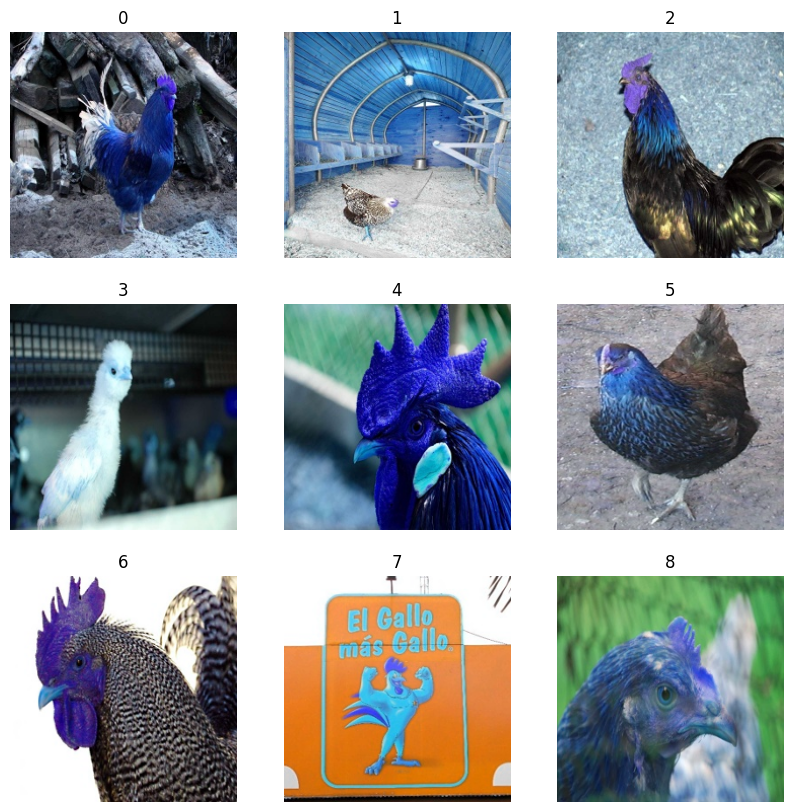

In [11]:
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(train_image[i])
    plt.title(i)
    plt.axis("off")

In [12]:
from sklearn.model_selection import train_test_split

train_x, val_x, train_y, val_y = train_test_split(train_x, train_y, test_size=0.1, random_state=42, stratify=train_y)

In [13]:
print("trainx shape",train_x.shape, "train y shape",train_y.shape, "valx shape",val_x.shape, "valy shape",val_y.shape)

trainx shape (1038, 224, 224, 3) train y shape (1038, 2) valx shape (116, 224, 224, 3) valy shape (116, 2)


100%|██████████| 1038/1038 [00:20<00:00, 49.83it/s]


The final training data shape is: (6228, 224, 224, 3) (6228, 2)


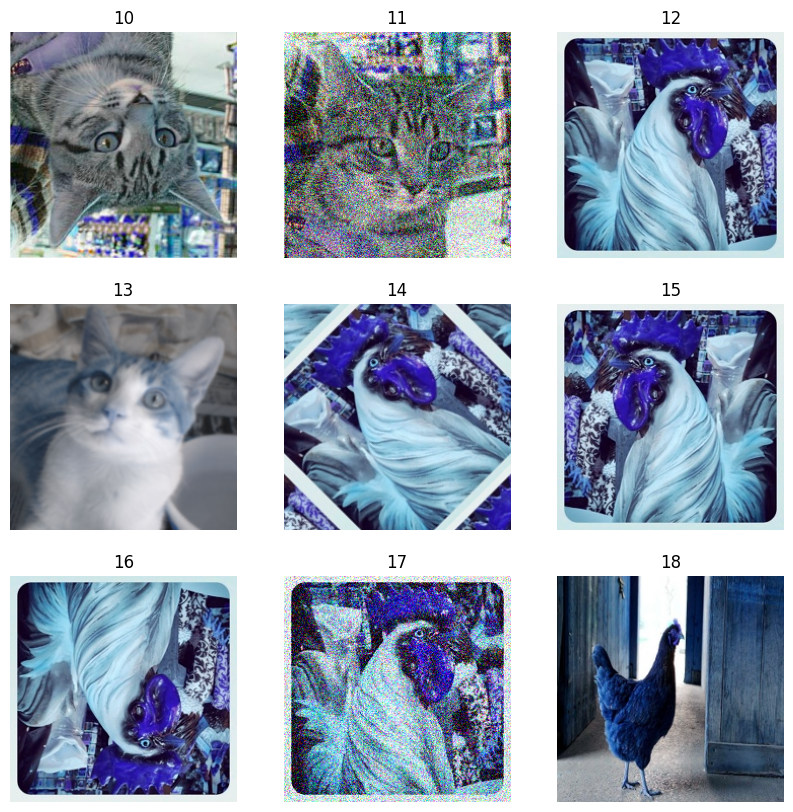

In [14]:
!pip install tqdm
import skimage.io as io
from skimage.transform import rotate, AffineTransform, warp
from skimage.util import random_noise
from skimage.filters import gaussian

from tqdm import tqdm
final_train_data = []
final_target_train = []
for i in tqdm(range(train_x.shape[0])):
    final_train_data.append(train_x[i])
    final_train_data.append(gaussian(image,sigma=1)) #Gaussian blur
    final_train_data.append(rotate(train_x[i], angle=45, mode = 'wrap')) #Rotate by 45 degree
    final_train_data.append(np.fliplr(train_x[i])) #flip left-right
    final_train_data.append(np.flipud(train_x[i]))  #flip up-down
    final_train_data.append(random_noise(train_x[i],var=0.2**2))  #Add random noise
    for j in range(6):  #Total five copy of original image including original one
        final_target_train.append(train_y[i])

#len(final_target_train), len(final_train_data)
final_data_train = np.array(final_train_data)
final_target_train = np.array(final_target_train)
print("The final training data shape is:",final_data_train.shape, final_target_train.shape)

#Display Some Samples from training set (Orginal + Augmented)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(final_train_data[i+10])
    plt.title(i+10)
    plt.axis("off")
plt.show()

In [21]:
drive_save_path = mydrive_path._str
os.makedirs(drive_save_path, exist_ok=True)

train_file = os.path.join(drive_save_path, 'Dataset_image_train.npz')
val_file = os.path.join(drive_save_path, 'Dataset_image_val.npz')
#************************************ Saving dataset into .npz file format **********************************#
np.savez(train_file, image_train=final_data_train, labels_train=final_target_train)
np.savez(val_file , image_val=val_x, labels_val=val_y)

'/content/drive/MyDrive'